In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve)

df = pd.read_csv(r'C:\Users\orams\Documents\Customer-Churn-Prediction\data\processed_data\telco_churn_ml_ready.csv')
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
#TASK1: FINAL MODEL EVALUATION

Accuracy: 0.7324343506032647
Precision: 0.49747899159663866
Recall: 0.7914438502673797
F1-score: 0.6109391124871001
ROC-AUC: 0.8421271538918598


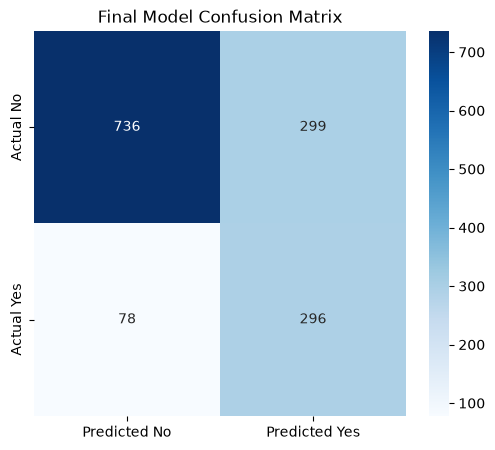

In [5]:
final_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Final Model Confusion Matrix')
plt.savefig('final_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

With *Accuracy* out of every 100 customers the model predicts 73 will churn or stay. *Precision* Out of every 100 customers predicted tochurn about 50 will really leave. *Recall*  Out of every 100 customers who actually leave, the model catches about 79. *F1-score* The model's balance between precision and recall is about 61%, reflecting its ability to identify churners while limiting false alarms. *ROC-AUC*: The model has an 84.2% ability to distinguish between customers who churn and those who stay across different classification thresholds.

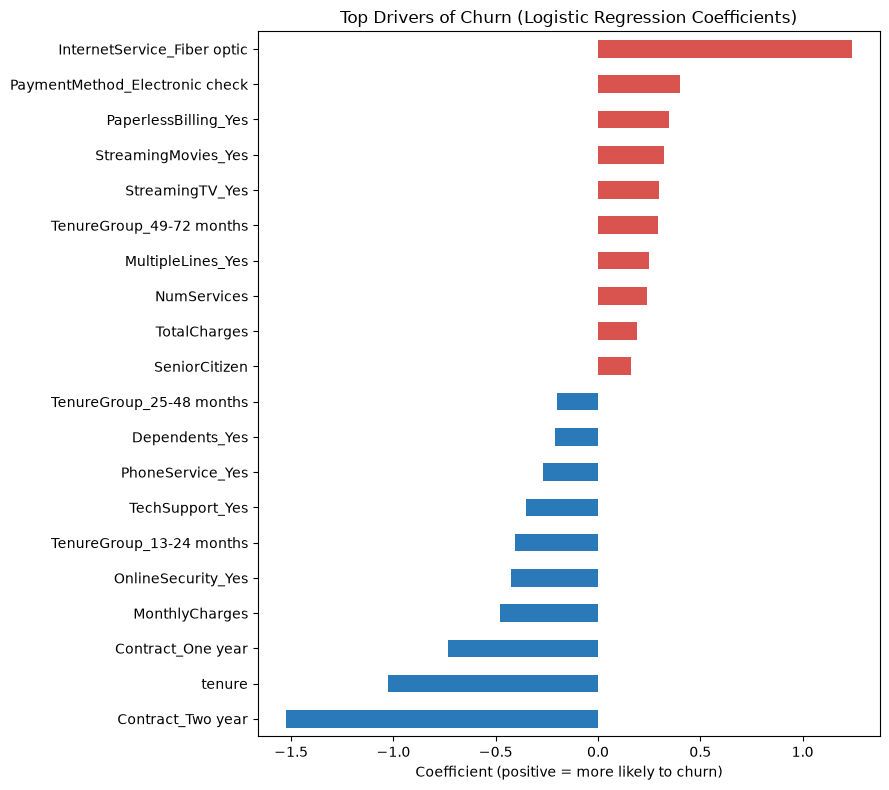

Strongest increase in churn risk:
 InternetService_Fiber optic       1.240006
PaymentMethod_Electronic check    0.400423
PaperlessBilling_Yes              0.345764
StreamingMovies_Yes               0.323337
StreamingTV_Yes                   0.300198
TenureGroup_49-72 months          0.294115
MultipleLines_Yes                 0.250704
NumServices                       0.238426
dtype: float64

Strongest decrease in churn risk:
 Contract_Two year          -1.524516
tenure                     -1.028162
Contract_One year          -0.730819
MonthlyCharges             -0.476583
OnlineSecurity_Yes         -0.423819
TenureGroup_13-24 months   -0.403854
TechSupport_Yes            -0.351325
PhoneService_Yes           -0.267045
dtype: float64


In [6]:
#TASK 2: Feature Importance
coefs = pd.Series(final_model.coef_[0], index=X.columns).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(9, 8))
top.plot(kind='barh', color=['#2a7ab9' if v < 0 else '#d9534f' for v in top])
plt.title('Top Drivers of Churn (Logistic Regression Coefficients)')
plt.xlabel('Coefficient (positive = more likely to churn)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Strongest increase in churn risk:\n", coefs.tail(8)[::-1])
print("\nStrongest decrease in churn risk:\n", coefs.head(8))

1. *What are the strongest predictors of churn?* InternetService Fiber optic is the strongest positive predictor, second Payment Methodd, Electronic check and Paperless Billing. These features are associated with higher churn risk. Contract_Two year has the strongest negative coefficient, suggesting a lower likelihood of churn.
2. *Which customer characteristics signal high risk?* Customers using fiber optic internetpaying using electronic check and using paperless billing show higher churn risk in this model.Customers with streaming services and multiple phone lines also have positive coefficients. These are associations, not proof that these characteristics cause churn.
3. *Which services or contract types matter most?* Fiber-optic internet has the strongest positive coefficient among the listed features. For contracts, month-to-month customers are the reference category, while one-year and two-year contracts have negative coefficients, especially two-year contracts. Online security and tech support also have negative coefficients, suggesting that customers with these services are less likely to churn according to the model.

In [7]:
#Task 3: Error analysis
results = X_test.copy()
results['actual'] = y_test.values
results['pred'] = y_pred

tp = results[(results.actual == 1) & (results.pred == 1)]
fn = results[(results.actual == 1) & (results.pred == 0)]
fp = results[(results.actual == 0) & (results.pred == 1)]
tn = results[(results.actual == 0) & (results.pred == 0)]
print("TP:", len(tp), "FN:", len(fn), "FP:", len(fp), "TN:", len(tn))

cols = ['tenure', 'MonthlyCharges', 'Contract_One year', 'Contract_Two year',
        'PaymentMethod_Electronic check', 'InternetService_Fiber optic']
cols = [c for c in cols if c in results.columns]
profile = pd.DataFrame({
    'Caught churners (TP)': tp[cols].mean(),
    'Missed churners (FN)': fn[cols].mean(),
    'False alarms (FP)': fp[cols].mean(),
})
print(profile.round(2))

TP: 296 FN: 78 FP: 299 TN: 736
                                Caught churners (TP)  Missed churners (FN)  \
tenure                                         -0.79                 -0.09   
MonthlyCharges                                  0.38                 -0.15   
Contract_One year                               0.03                  0.35   
Contract_Two year                               0.00                  0.12   
PaymentMethod_Electronic check                  0.63                  0.24   
InternetService_Fiber optic                     0.77                  0.31   

                                False alarms (FP)  
tenure                                      -0.45  
MonthlyCharges                               0.41  
Contract_One year                            0.09  
Contract_Two year                            0.00  
PaymentMethod_Electronic check               0.55  
InternetService_Fiber optic                  0.70  


1. *Comparison. Missed Churners vs Caught Churners*. Missed churners usually have longer tenure and lower monthly charges than caught churners making them appear less likely to leave. Also they are more liekly to have one year or two year contracts  and less likely to use electronic check or fiber-optic internet. These characteristics may make the model underestimate their churn risk.
2. *Why Each Error Matters to the Business*. 78 missed churners being false negatives. They are customers who actually churn but are predicted to stay. The business may lose the chnace to give them retentive support losing customers and their prospective revenue.

In [ ]:
#WRITE UPS

## Final Model Evaluation

The final model is class-weighted Logistic Regression, evaluated on the held-out test set of 1,409 customers.

- **Accuracy (73.2%):** Out of every 100 customers, the model's prediction is correct for about 73.
- **Precision (49.7%):** Out of every 100 customers the model predicts will churn, about 50 really leave.
- **Recall (79.1%):** Out of every 100 customers who actually leave, the model catches about 79.
- **F1-score (61.1%):** The balance between precision and recall is about 61%, reflecting the model's ability to identify churners while limiting false alarms.
- **ROC-AUC (84.2%):** If one customer who left and one who stayed are picked at random, the model gives the customer who left the higher risk score about 84% of the time.

## Feature Importance

**Strongest predictors of churn.** By size, the largest coefficients are Contract_Two year (-1.52), InternetService_Fiber optic (+1.24), tenure (-1.03) and Contract_One year (-0.73). Contract length and fiber optic internet are the two biggest drivers. Electronic check (+0.40) and paperless billing (+0.35) follow among the factors that raise risk.

**Customer characteristics that signal high risk.** Customers on fiber optic internet, paying by electronic check, using paperless billing, streaming services or multiple phone lines show higher churn risk. These are associations, not proof that these characteristics cause churn.

**Services and contract types that matter most.** Month-to-month is the reference category, so one-year and two-year contracts have negative coefficients, especially two-year. Online security (-0.42) and tech support (-0.35) are also negative, suggesting customers with these services are less likely to churn.

**Agreement with the EDA.** The model confirms the Week 2 findings on contract type, fiber optic, electronic check and tenure.

**Caution.** MonthlyCharges (-0.48) and TenureGroup_49-72 months (+0.29) look like they contradict the EDA. This is a collinearity effect, because fiber and streaming already capture price, and tenure overlaps with TenureGroup and TotalCharges. Coefficients for overlapping features should not be read in isolation.

## Error Analysis

The model produced 296 true positives, 78 false negatives, 299 false positives and 736 true negatives.

**Missed churners versus caught churners.** Missed churners have longer tenure and lower monthly charges than caught churners. They are more likely to be on one-year or two-year contracts and less likely to use electronic check or fiber optic internet. They look low-risk to the model, so their risk is underestimated.

**False alarms.** The false alarms (fiber 0.70, electronic check 0.55) look similar to the caught churners. They are customers with a high-risk profile who stayed, which is why they are hard to avoid.

**Why each error matters.**
- **False negatives (78):** These customers leave without the business getting a chance to offer retention support, so the company loses the customer and their future revenue.
- **False positives (299):** These customers receive retention offers they did not need, which wastes resources that could target customers more likely to leave.

In [8]:
internet = df[df['HasInternetService_Yes']]
for c in ['TechSupport_Yes', 'OnlineSecurity_Yes']:
    print(c)
    print(internet.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean()).round(3))

TechSupport_Yes
TechSupport_Yes
False    0.416
True     0.152
Name: Churn, dtype: float64
OnlineSecurity_Yes
OnlineSecurity_Yes
False    0.418
True     0.146
Name: Churn, dtype: float64


## Business Recommendations

The recommendations below are based on this project's findings. They show association, not proven cause, so expected benefits are stated as likely rather than guaranteed.

1. **Encourage longer contracts.**
   - *Finding:* Churn is 42.7% on month-to-month contracts, versus 11.3% on one-year and 2.8% on two-year. Contract_Two year is the strongest coefficient in the model (-1.52).
   - *Action:* Offer discounts or perks to month-to-month customers who move to a one-year or two-year plan.
   - *Expected benefit:* Moving customers off month-to-month is likely to reduce churn in the group that currently leaves most.

2. **Move electronic check users to automatic payment.**
   - *Finding:* Electronic check customers churn at 45.3%, versus 15.2% to 19.1% for the other payment methods.
   - *Action:* Offer a small incentive to switch to bank transfer or credit card auto-pay.
   - *Expected benefit:* Removing the manual payment step may reduce the friction that is associated with leaving.

3. **Review fiber optic quality and pricing.**
   - *Finding:* Fiber optic customers churn at 41.9%, versus 19.0% for DSL, and fiber has the strongest positive coefficient (+1.24).
   - *Action:* Investigate service reliability and price competitiveness for fiber customers, and run satisfaction checks on this group.
   - *Expected benefit:* Fixing the cause of dissatisfaction in the highest-risk service tier could lower churn where it is concentrated.

4. **Launch an early onboarding program.**
   - *Finding:* Churned customers have a median tenure of about 10 months, versus about 38 for customers who stayed.
   - *Action:* Run check-ins, setup help and offers during the first 12 months.
   - *Expected benefit:* Supporting customers while they are still deciding whether to stay is likely to reduce early churn.

5. **Bundle tech support and online security.**
   - *Finding:* Among customers with internet service, churn is 15.2% for those with tech support versus 41.6% for those without, and 14.6% for those with online security versus 41.8% for those without. Both services also have negative model coefficients (-0.35 and -0.42).
   - *Action:* Offer a free trial or discounted bundle of these services to at-risk internet customers who do not have them.
   - *Expected benefit:* Customers who use these services may become more attached to the company. This needs testing, since customers who choose these services may already be more loyal, so the data shows association only.

6. **Give senior citizens targeted support.**
   - *Finding:* Senior citizens churn at 41.7%, versus 23.6% for other customers.
   - *Action:* Provide simpler plans, phone-based support and proactive outreach.
   - *Expected benefit:* Meeting this group's needs more directly may narrow the churn gap.

7. **Use the model to target retention spending.**
   - *Finding:* The model flags about 595 customers and catches 296 of the 374 who actually left, but half of its flags are false alarms.
   - *Action:* Rank customers by churn probability. Call only the top tier, send low-cost offers to the medium tier, and only monitor the low tier.
   - *Expected benefit:* Costly interventions go to the customers most likely to leave, which limits wasted offers.